Checking the GPU resource which is available

Verifying the runtime availability

In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cpu
CUDA available: False


In [ ]:
!nvidia-smi

/bin/bash: line 1: nvidia-smi: command not found


Installment and Verification of Ultralytics

In [ ]:
%pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 22.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 7.9 MB/s eta 0:00:00


In [18]:
from ultralytics import YOLO
import torch

print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))


CUDA available: True
GPU: Tesla T4


Dowloading the roboflow weapon detection dataset directly through colab

In [ ]:
%pip install -q roboflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 373.9/373.9 kB 11.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 51.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 2.3 MB/s eta 0:00:00


In [ ]:
import roboflow

roboflow.login()

roboflow.download_dataset(
    dataset_url="https://universe.roboflow.com/projects-l2904/person-weapon-knife-detection/1",
    model_format="yolov8"
)

visit https://app.roboflow.com/auth-cli to get your authentication token.
Paste the authentication token here: ··········
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to person-weapon-knife-detection-1 in yolov8:: 100%|██████████| 28617/28617 [00:04<00:00, 5821.16it/s] 


Checking the dataset structure

In [ ]:
from pathlib import Path

dataset_dir = Path("/content/person-weapon-knife-detection-1")

print("Dataset exists:", dataset_dir.exists())

for path in sorted(dataset_dir.iterdir()):
    print(path.name)

Dataset exists: True
README.dataset.txt
README.roboflow.txt
data.yaml
test
train
valid


Reading the dataset's actual classes and the paths for training, validation, and testing

In [ ]:
import yaml

yaml_path = dataset_dir / "data.yaml"

with open(yaml_path, "r") as f:
    config = yaml.safe_load(f)

print(config)

{'names': ['knife', 'person', 'weapon'], 'nc': 3, 'roboflow': {'license': 'CC BY 4.0', 'project': 'person-weapon-knife-detection', 'url': 'https://universe.roboflow.com/projects-l2904/person-weapon-knife-detection/dataset/1', 'version': 1, 'workspace': 'projects-l2904'}, 'test': '../test/images', 'train': '../train/images', 'val': '../valid/images'}


Visualizing the annotations by inspecting five training images with their bounding box

knife_996_jpg.rf.335f7937449ca6d93e44ead17441267a.jpg


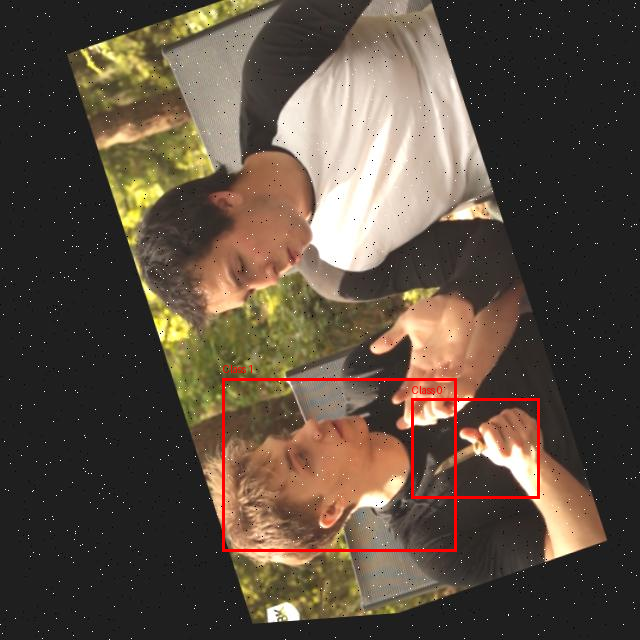

sharpenKnife200_jpg.rf.bf31de6375170cc76dc66a947c9b4a1e.jpg


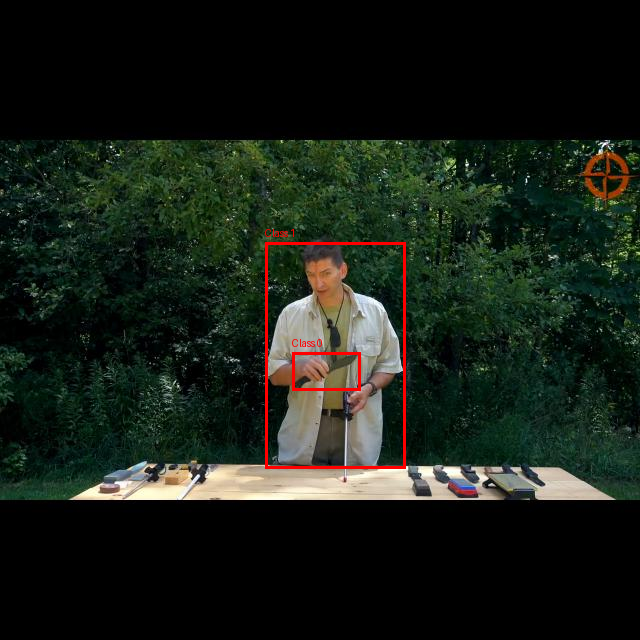

amfin982_jpg.rf.f6dea223fadda2fb40fb4bf709f80244.jpg


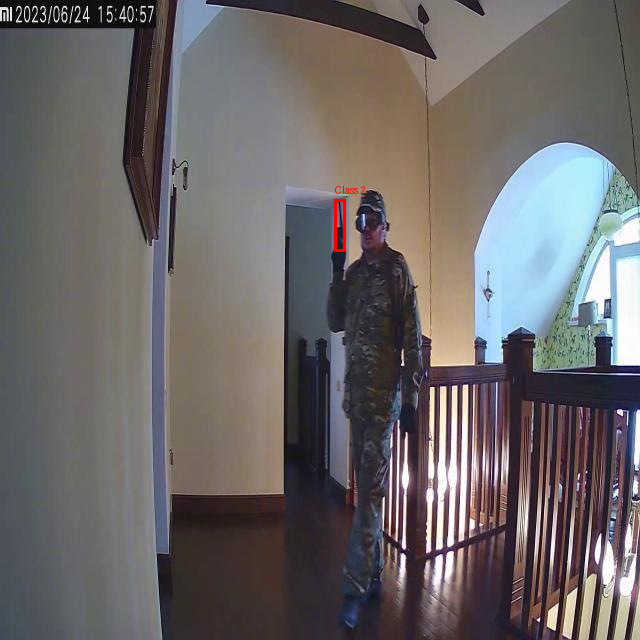

3RCJDSAF6D4N_jpg.rf.c380f82e860c08ad1053d906e3329432.jpg


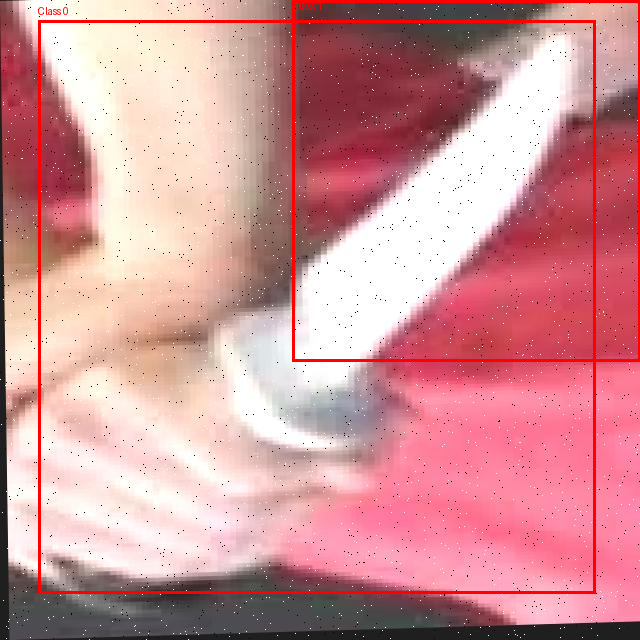

armas-1975-_jpg.rf.9d8153c6db0f1ee3b81ded6dc02fd82b.jpg


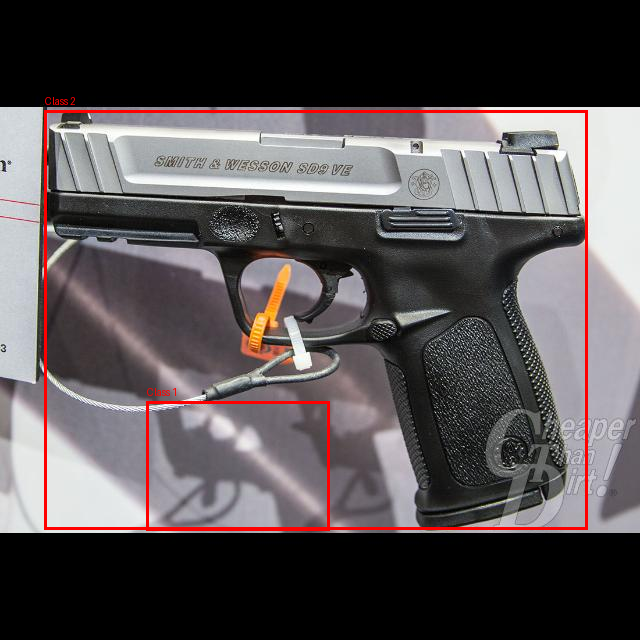

In [ ]:
from IPython.display import display
from PIL import Image, ImageDraw
import random

images_dir = dataset_dir / "train" / "images"
labels_dir = dataset_dir / "train" / "labels"

image_files = list(images_dir.glob("*"))
random.seed(42)
random.shuffle(image_files)

for image_path in image_files[:5]:
    label_path = labels_dir / f"{image_path.stem}.txt"

    image = Image.open(image_path).convert("RGB")
    draw = ImageDraw.Draw(image)
    width, height = image.size

    if label_path.exists():
        for line in label_path.read_text().splitlines():
            values = line.split()
            if len(values) != 5:
                continue

            cls, xc, yc, bw, bh = map(float, values)

            x1 = (xc - bw / 2) * width
            y1 = (yc - bh / 2) * height
            x2 = (xc + bw / 2) * width
            y2 = (yc + bh / 2) * height

            draw.rectangle((x1, y1, x2, y2), outline="red", width=3)
            draw.text((x1, max(0, y1 - 15)), f"Class {int(cls)}", fill="red")

    print(image_path.name)
    display(image.resize((640, int(640 * height / width))))

Auditing the dataset before training for checking the number of images, label files, and annotations for each class across all three splits

In [ ]:
from pathlib import Path
from collections import Counter

dataset_dir = Path("/content/person-weapon-knife-detection-1")

class_names = ["knife", "person", "weapon"]
splits = {
    "train": "train",
    "validation": "valid",
    "test": "test"
}

for split_name, folder in splits.items():
    images_dir = dataset_dir / folder / "images"
    labels_dir = dataset_dir / folder / "labels"

    images = [
        p for p in images_dir.iterdir()
        if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
    ]

    counts = Counter()
    missing_labels = 0
    invalid_lines = 0

    for image_path in images:
        label_path = labels_dir / f"{image_path.stem}.txt"

        if not label_path.exists():
            missing_labels += 1
            continue

        for line in label_path.read_text().splitlines():
            values = line.split()

            if len(values) != 5:
                invalid_lines += 1
                continue

            try:
                cls, x, y, w, h = map(float, values)
                if (
                    cls.is_integer()
                    and 0 <= int(cls) < len(class_names)
                    and all(0 <= v <= 1 for v in (x, y, w, h))
                    and w > 0 and h > 0
                ):
                    counts[class_names[int(cls)]] += 1
                else:
                    invalid_lines += 1
            except ValueError:
                invalid_lines += 1

    print(f"\n{split_name.upper()}")
    print("Images:", len(images))
    print("Missing label files:", missing_labels)
    print("Invalid annotation lines:", invalid_lines)
    print("Object counts:", dict(counts))


TRAIN
Images: 12718
Missing label files: 0
Invalid annotation lines: 420
Object counts: {'weapon': 8895, 'person': 7693, 'knife': 5027}

VALIDATION
Images: 799
Missing label files: 0
Invalid annotation lines: 20
Object counts: {'weapon': 534, 'knife': 334, 'person': 445}

TEST
Images: 789
Missing label files: 0
Invalid annotation lines: 18
Object counts: {'knife': 304, 'person': 495, 'weapon': 576}


Inspecting the invalid annotations

In [ ]:
from pathlib import Path
import math

dataset_dir = Path("/content/person-weapon-knife-detection-1")

for split in ["train", "valid", "test"]:
    labels_dir = dataset_dir / split / "labels"
    found = 0

    print(f"\n--- {split.upper()} ---")

    for label_path in labels_dir.glob("*.txt"):
        for line_no, line in enumerate(
            label_path.read_text().splitlines(), start=1
        ):
            values = line.split()
            reason = None

            if len(values) != 5:
                reason = "Expected 5 values"

            else:
                try:
                    vals = list(map(float, values))
                    cls, x, y, w, h = vals

                    if not all(math.isfinite(v) for v in vals):
                        reason = "Non-finite value"
                    elif not cls.is_integer() or not 0 <= int(cls) < 3:
                        reason = "Invalid class ID"
                    elif not all(0 <= v <= 1 for v in (x, y, w, h)):
                        reason = "Coordinate/size outside [0, 1]"
                    elif w <= 0 or h <= 0:
                        reason = "Non-positive box size"

                except ValueError:
                    reason = "Non-numeric value"

            if reason:
                print(
                    f"{label_path.name}, line {line_no}: "
                    f"{reason} | {line}"
                )
                found += 1

                if found >= 5:
                    break

        if found >= 5:
            break

    if found == 0:
        print("No invalid lines found by this check.")


--- TRAIN ---
-2022-09-08-12-27-46_png_jpg.rf.10469027ce88e76d3275892ac2e2e2d8.txt, line 1: Expected 5 values | 1 0.4578125 0.2203125 0.4703125 0.21875 0.484375 0.221875 0.49375 0.2265625 0.49375 0.2328125 0.4859375 0.2328125 0.4703125 0.240625 0.4609375 0.240625 0.4578125 0.2375 0.4609375 0.23125 0.459375 0.221875
-2022-09-08-12-27-46_png_jpg.rf.10469027ce88e76d3275892ac2e2e2d8.txt, line 2: Expected 5 values | 1 0.60625 0.74375 0.6171875 0.740625 0.634375 0.740625 0.6390625 0.7453125 0.6359375 0.7484375 0.615625 0.7484375 0.60625 0.7453125
-2022-09-08-12-27-46_png_jpg.rf.10469027ce88e76d3275892ac2e2e2d8.txt, line 3: Expected 5 values | 1 0.571875 0.653125 0.578125 0.65625 0.5796875 0.6609375 0.5765625 0.665625 0.56875 0.6671875 0.5484375 0.6625 0.5484375 0.65625 0.553125 0.65 0.5703125 0.653125
01-08-2022__10-03-24AM_jpg.rf.4031b813becd47f82dd8a012c243f943.txt, line 1: Expected 5 values | 1 0.121875 0.146875 0.125 0.1453125 0.1296875 0.146875 0.134375 0.1609375 0.1328125 0.1640625 0.

The examples contain many coordinate pairs after the class ID, which is the format used for polygon segmentation annotations, not ordinary YOLO bounding boxes.

We should preserve these polygons and convert them properly to YOLO detection boxes rather than discard them. The conversion should use the minimum and maximum polygon coordinates to form a bounding rectangle.

Converting the annotations safely by creating new dataset and leaving the original one unchanged.

It preserves existing valid bounding boxes and converts polygon annotations into bounding rectangles.

In [ ]:
from pathlib import Path
from collections import Counter
import shutil
import math
import yaml

source = Path("/content/person-weapon-knife-detection-1")
output = Path("/content/weapon-detection-yolo")

class_names = ["knife", "person", "weapon"]
splits = ["train", "valid", "test"]

stats = Counter()

for split in splits:
    src_images = source / split / "images"
    src_labels = source / split / "labels"
    dst_images = output / split / "images"
    dst_labels = output / split / "labels"

    if not src_images.exists() or not src_labels.exists():
        raise FileNotFoundError(f"Missing images or labels for {split}")

    dst_images.parent.mkdir(parents=True, exist_ok=True)
    dst_labels.mkdir(parents=True, exist_ok=True)

    if not dst_images.exists():
        shutil.copytree(src_images, dst_images)

    for label_file in src_labels.glob("*.txt"):
        converted = []

        for line in label_file.read_text().splitlines():
            parts = line.split()

            try:
                if len(parts) < 5:
                    stats["skipped"] += 1
                    continue

                values = [float(v) for v in parts]
                cls_value = values[0]

                if (
                    not math.isfinite(cls_value)
                    or not cls_value.is_integer()
                    or not 0 <= int(cls_value) < len(class_names)
                    or not all(math.isfinite(v) for v in values)
                ):
                    stats["skipped"] += 1
                    continue

                cls = int(cls_value)

                if len(values) == 5:
                    # Existing YOLO bounding box
                    _, x, y, w, h = values

                    if (
                        not all(0 <= v <= 1 for v in (x, y, w, h))
                        or w <= 0 or h <= 0
                    ):
                        stats["skipped"] += 1
                        continue

                    converted.append(
                        f"{cls} {x:.6f} {y:.6f} {w:.6f} {h:.6f}"
                    )
                    stats["boxes_preserved"] += 1

                else:
                    # YOLO polygon: class followed by x,y coordinate pairs
                    coords = values[1:]

                    if len(coords) < 6 or len(coords) % 2 != 0:
                        stats["skipped"] += 1
                        continue

                    if not all(0 <= v <= 1 for v in coords):
                        stats["skipped"] += 1
                        continue

                    xs = coords[0::2]
                    ys = coords[1::2]

                    x_min, x_max = min(xs), max(xs)
                    y_min, y_max = min(ys), max(ys)

                    w = x_max - x_min
                    h = y_max - y_min

                    if w <= 0 or h <= 0:
                        stats["skipped"] += 1
                        continue

                    x_center = (x_min + x_max) / 2
                    y_center = (y_min + y_max) / 2

                    converted.append(
                        f"{cls} {x_center:.6f} {y_center:.6f} "
                        f"{w:.6f} {h:.6f}"
                    )
                    stats["polygons_converted"] += 1

            except (ValueError, OverflowError):
                stats["skipped"] += 1

        (dst_labels / label_file.name).write_text(
            "\n".join(converted),
            encoding="utf-8"
        )

config = {
    "path": str(output),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "names": class_names
}

with open(output / "data.yaml", "w", encoding="utf-8") as f:
    yaml.safe_dump(config, f, sort_keys=False)

print("Conversion complete.")
print("Output:", output)
print("Statistics:", dict(stats))
print("Config:", config)

Conversion complete.
Output: /content/weapon-detection-yolo
Statistics: {'boxes_preserved': 24303, 'polygons_converted': 458}
Config: {'path': '/content/weapon-detection-yolo', 'train': 'train/images', 'val': 'valid/images', 'test': 'test/images', 'names': ['knife', 'person', 'weapon']}


Again visualizing five converted images

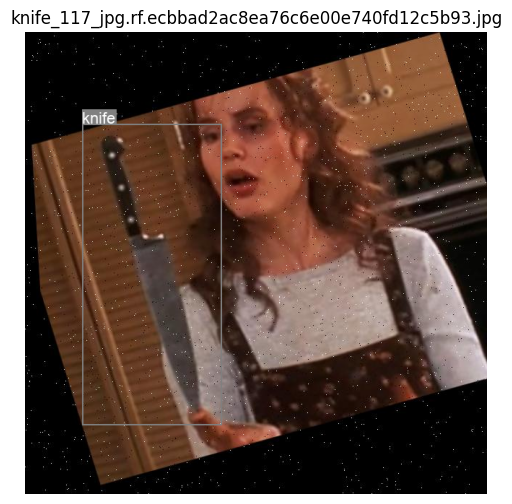

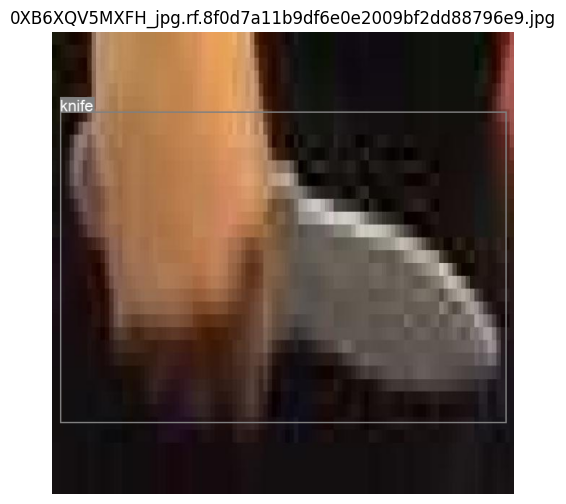

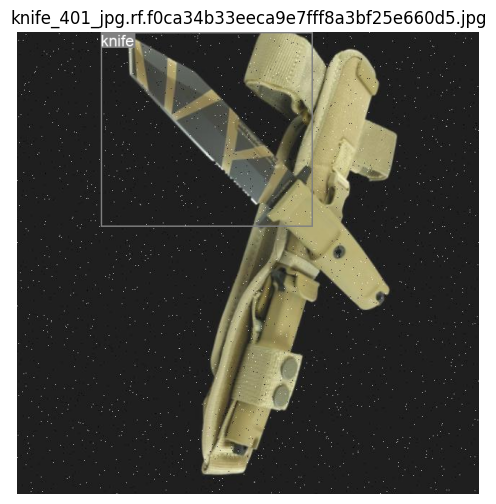

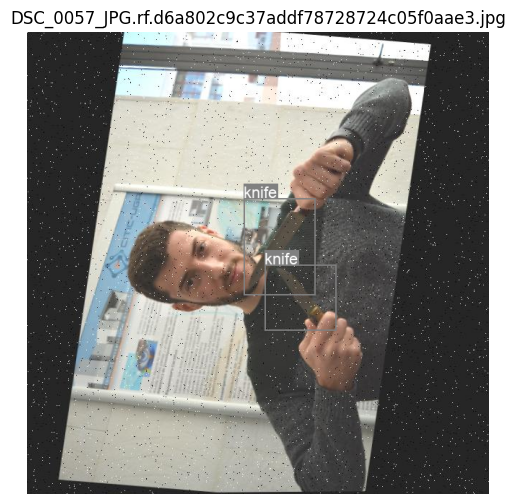

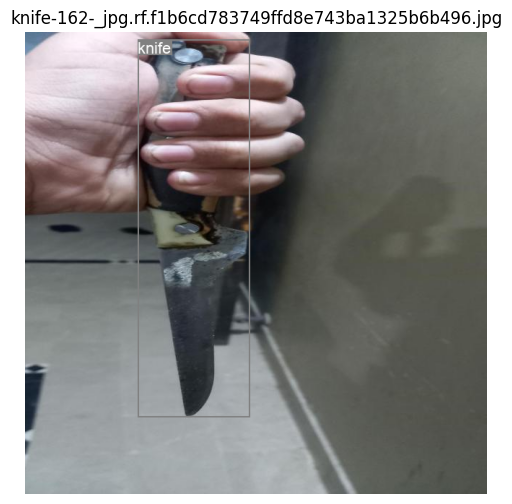

In [ ]:
from pathlib import Path
import random
import matplotlib.pyplot as plt
from PIL import Image
from ultralytics.utils.plotting import Annotator, colors

dataset = Path("/content/weapon-detection-yolo")
class_names = ["knife", "person", "weapon"]

image_files = list((dataset / "train/images").glob("*"))
image_files = [p for p in image_files if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".webp"]]

for image_path in random.sample(image_files, min(5, len(image_files))):
    label_path = dataset / "train/labels" / f"{image_path.stem}.txt"

    image = Image.open(image_path).convert("RGB")
    annotator = Annotator(image.copy())

    if label_path.exists():
        for line in label_path.read_text().splitlines():
            values = line.split()
            if len(values) != 5:
                continue

            cls, xc, yc, w, h = map(float, values)
            W, H = image.size

            box = [
                (xc - w / 2) * W,
                (yc - h / 2) * H,
                (xc + w / 2) * W,
                (yc + h / 2) * H,
            ]

            annotator.box_label(box, class_names[int(cls)])

    plt.figure(figsize=(8, 6))
    plt.imshow(annotator.result())
    plt.title(image_path.name)
    plt.axis("off")
    plt.show()

Training a YOLO11n baseline using Tesla T4 GPU

In [ ]:
from ultralytics import YOLO

model = YOLO("yolo11n.pt")

results = model.train(
    data="/content/weapon-detection-yolo/data.yaml",
    epochs=10,
    imgsz=640,
    batch=16,
    device=0,
    workers=2,
    project="/content/runs/weapon",
    name="yolo11n_baseline",
    patience=5,
    plots=True
)

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/weapon-detection-yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo11n_baseline, nbs=64, nms=None, opset=None, 

Downloading the trained model

In [ ]:
from google.colab import files

files.download(
    "/content/runs/weapon/yolo11n_baseline/weights/best.pt"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Mounting to google drive

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


Copying the model to drive

In [ ]:
import shutil
from pathlib import Path

source = Path(
    "/content/runs/weapon/yolo11n_baseline/weights/best.pt"
)

destination = Path(
    "/content/drive/MyDrive/WeaponDetection/best.pt"
)

destination.parent.mkdir(parents=True, exist_ok=True)
shutil.copy2(source, destination)

print("Model saved to Google Drive:", destination)

Model saved to Google Drive: /content/drive/MyDrive/WeaponDetection/best.pt


After reconnecting, loading the saved model

In [ ]:
from ultralytics import YOLO

model = YOLO(
    "/content/drive/MyDrive/WeaponDetection/best.pt"
)

In [ ]:
from ultralytics import YOLO

model = YOLO(
    "/content/runs/weapon/yolo11n_baseline/weights/best.pt"
)

test_results = model.val(
    data="/content/weapon-detection-yolo/data.yaml",
    split="test",
    imgsz=640,
    batch=16,
    device=0,
    plots=True,
    project="/content/runs/weapon",
    name="test_evaluation"
)

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,537 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1603.5±666.8 MB/s, size: 41.6 KB)
val: Scanning /content/weapon-detection-yolo/test/labels... 789 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 789/789 2.0Kit/s 0.4s
val: New cache created: /content/weapon-detection-yolo/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 50/50 5.1it/s 9.9s
                   all        789       1393      0.766      0.656      0.735      0.479
                 knife        297        304      0.763      0.839      0.865      0.528
                person        319        513      0.706      0.468      0.586      0.389
                weapon        479        576      0.829      0.661      0.755      0.521
Speed: 1.6ms preprocess, 4.5ms inference, 0.0ms loss, 1

Inspecting predictions on real images

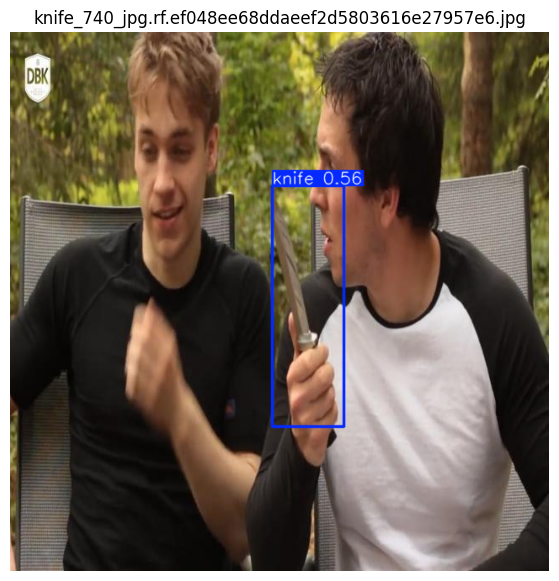

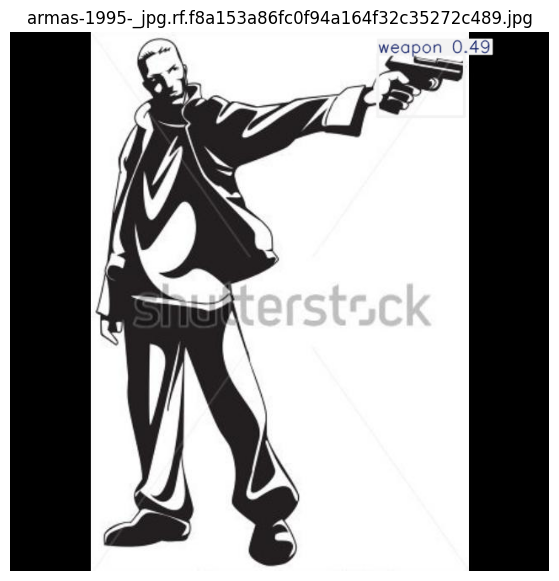

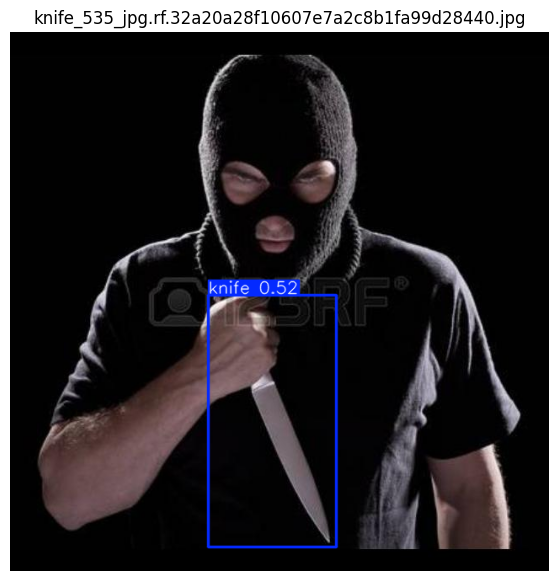

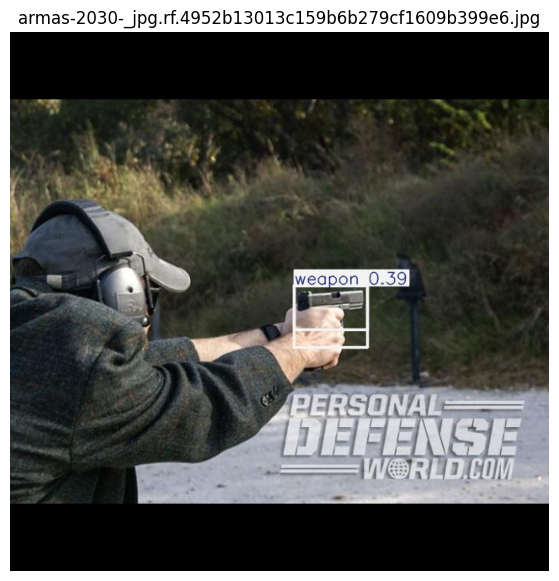

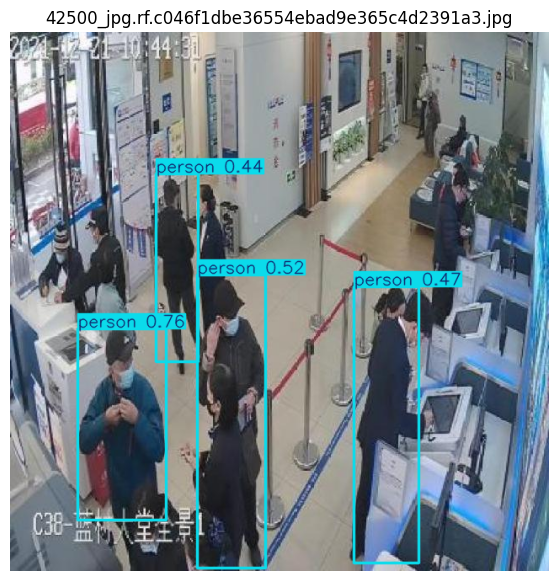

In [ ]:
from pathlib import Path
import random
import matplotlib.pyplot as plt
from ultralytics import YOLO

model = YOLO(
    "/content/runs/weapon/yolo11n_baseline/weights/best.pt"
)

test_dir = Path("/content/weapon-detection-yolo/test/images")
image_files = [
    p for p in test_dir.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".webp"]
]

samples = random.sample(image_files, min(5, len(image_files)))

results = model.predict(
    source=[str(p) for p in samples],
    imgsz=640,
    conf=0.25,
    device=0,
    verbose=False
)

for result in results:
    annotated = result.plot()
    plt.figure(figsize=(10, 7))
    plt.imshow(annotated[:, :, ::-1])
    plt.title(result.path.split("/")[-1])
    plt.axis("off")
    plt.show()

Uploading a test video to colab

In [ ]:
from google.colab import files

uploaded = files.upload()

Using yt-dlp for publicly accessible videos

In [ ]:
!pip -q install yt-dlp

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 183.7/183.7 kB 9.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 90.9 MB/s eta 0:00:00


In [ ]:
!pip -q install -U yt-dlp

In [ ]:
!yt-dlp \
  --no-playlist \
  -f "best" \
  --max-filesize 200M \
  --merge-output-format mp4 \
  -o "/content/test_video.%(ext)s" \
  "https://www.youtube.com/shorts/8TZRCA5G_yw"

         To let yt-dlp download and merge the best available formats, simply do not pass any format selection.
         If you know what you are doing and want only the best pre-merged format, use "-f b" instead to suppress this warning
[youtube] Extracting URL: https://www.youtube.com/shorts/8TZRCA5G_yw
[youtube] 8TZRCA5G_yw: Downloading webpage
[youtube] 8TZRCA5G_yw: Downloading visionos player API JSON
[youtube] 8TZRCA5G_yw: Downloading m3u8 information
ERROR: [youtube] 8TZRCA5G_yw: Requested format is not available. Use --list-formats for a list of available formats


Checking the available formats

In [ ]:
!yt-dlp --list-formats "https://www.youtube.com/shorts/8TZRCA5G_yw"

[youtube] Extracting URL: https://www.youtube.com/shorts/8TZRCA5G_yw
[youtube] 8TZRCA5G_yw: Downloading webpage
[youtube] 8TZRCA5G_yw: Downloading visionos player API JSON
[youtube] 8TZRCA5G_yw: Downloading m3u8 information
[info] Available formats for 8TZRCA5G_yw:
ID      EXT   RESOLUTION FPS CH │    FILESIZE   TBR PROTO │ VCODEC          VBR ACODEC      ABR ASR MORE INFO
──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
sb0     mhtml 48x27        8    │                   mhtml │ images                                  storyboard
233     mp4   audio only        │                   m3u8  │ audio only          unknown             Default, low
234     mp4   audio only        │                   m3u8  │ audio only          unknown             Default, high
139-drc m4a   audio only      2 │    72.46KiB   49k https │ audio only          mp4a.40.5   49k 22k low, DRC, m4a_dash
249-drc webm  audio only      2 │    65.51Ki

Downloading the youtube short

In [ ]:
!yt-dlp \
  -f "136+140/136" \
  --max-filesize 200M \
  --merge-output-format mp4 \
  -o "/content/test_video.%(ext)s" \
  "https://www.youtube.com/shorts/8TZRCA5G_yw"

[youtube] Extracting URL: https://www.youtube.com/shorts/8TZRCA5G_yw
[youtube] 8TZRCA5G_yw: Downloading webpage
[youtube] 8TZRCA5G_yw: Downloading visionos player API JSON
[youtube] 8TZRCA5G_yw: Downloading m3u8 information
[info] 8TZRCA5G_yw: Downloading 1 format(s): 136+140
[download] Destination: /content/test_video.f136.mp4
[download] 100% of    1.34MiB in 00:00:00 at 4.58MiB/s
[download] Destination: /content/test_video.f140.m4a
[download] 100% of  190.19KiB in 00:00:00 at 575.50KiB/s
[Merger] Merging formats into "/content/test_video.mp4"
Deleting original file /content/test_video.f136.mp4 (pass -k to keep)
Deleting original file /content/test_video.f140.m4a (pass -k to keep)


Running the weapon detection on the video.

It will process the video using your trained YOLO11n model and save the annotated video with detection boxes and confidence scores.

In [ ]:
from ultralytics import YOLO

model = YOLO(
    "/content/runs/weapon/yolo11n_baseline/weights/best.pt"
)

results = model.predict(
    source="/content/test_video.mp4",
    imgsz=640,
    conf=0.25,
    device=0,
    save=True,
    project="/content/runs/weapon",
    name="youtube_video_demo"
)

print("Video processing complete.")
print("Output folder: /content/runs/weapon/youtube_video_demo")


WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

video 1/1 (frame 1/354) /content/test_video.mp4: 640x384 (no detections), 8.5ms
video 1/1 (frame 2/354) /content/test_video.mp4: 640x384 (no detections), 11.9ms
video 1/1 (frame 3/354) /content/test_video.mp4: 640x384 (no detections), 11.5ms
video 1/1 (frame 4/354) /content/test_video.mp4: 640x384 (no detections), 9.4ms
video 1/1 (frame 5/354) /content/test_video.mp4: 640x384 (no detections), 19.5ms
video 1/1 (frame 6/354) /content/test_video.mp4: 640x384

Finding the output video

In [ ]:
import glob
print(glob.glob("/content/runs/weapon/youtube_video_demo/*"))

['/content/runs/weapon/youtube_video_demo/test_video.avi']


Watching the detection video in colab

In [ ]:
from IPython.display import Video, display

video_path = "/content/runs/weapon/youtube_video_demo/test_video.avi"

display(Video(video_path, embed=True, width=480))

Downloading the annotated video

In [ ]:
from google.colab import files

files.download("/content/runs/weapon/youtube_video_demo/test_video.avi")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Measuring actual video processing FPS.

Measures how quickly your model processes the video frame by frame, including preprocessing and postprocessing

In [ ]:
import cv2
import time
from ultralytics import YOLO

video_path = "/content/test_video.mp4"
model_path = "/content/runs/weapon/yolo11n_baseline/weights/best.pt"

model = YOLO(model_path)
cap = cv2.VideoCapture(video_path)

if not cap.isOpened():
    raise RuntimeError("Could not open the input video.")

total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
video_fps = cap.get(cv2.CAP_PROP_FPS)

processed_frames = 0
frames_with_detections = 0
start = time.perf_counter()

while True:
    success, frame = cap.read()
    if not success:
        break

    result = model.predict(
        source=frame,
        imgsz=640,
        conf=0.25,
        device=0,
        verbose=False
    )[0]

    processed_frames += 1

    if result.boxes is not None and len(result.boxes) > 0:
        frames_with_detections += 1

elapsed = time.perf_counter() - start
cap.release()

print(f"Input video FPS: {video_fps:.2f}")
print(f"Total frames in video: {total_frames}")
print(f"Processed frames: {processed_frames}")
print(f"Frames with detections: {frames_with_detections}")
print(f"Processing time: {elapsed:.2f} seconds")
print(f"Actual processing FPS: {processed_frames / elapsed:.2f}")
print(f"Average time per frame: {elapsed / processed_frames * 1000:.2f} ms")

Input video FPS: 29.71
Total frames in video: 354
Processed frames: 354
Frames with detections: 65
Processing time: 4.77 seconds
Actual processing FPS: 74.18
Average time per frame: 13.48 ms


Adding a simple weapon detection event log.

Generate a CSV log of detections, including timestamps, classes, confidence scores, and bounding boxes.

In [ ]:
import cv2
import csv
from ultralytics import YOLO

video_path = "/content/test_video.mp4"
output_csv = "/content/weapon_detection_events.csv"

model = YOLO(
    "/content/runs/weapon/yolo11n_baseline/weights/best.pt"
)

cap = cv2.VideoCapture(video_path)
video_fps = cap.get(cv2.CAP_PROP_FPS) or 30.0

event_count = 0

with open(output_csv, "w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow([
        "timestamp_seconds",
        "frame_number",
        "class_name",
        "confidence",
        "x1", "y1", "x2", "y2"
    ])

    frame_number = 0

    while True:
        success, frame = cap.read()
        if not success:
            break

        result = model.predict(
            frame,
            imgsz=640,
            conf=0.25,
            device=0,
            verbose=False
        )[0]

        if result.boxes is not None:
            for box in result.boxes:
                class_id = int(box.cls.item())
                class_name = model.names[class_id]
                confidence = float(box.conf.item())
                x1, y1, x2, y2 = map(
                    int, box.xyxy[0].tolist()
                )

                writer.writerow([
                    round(frame_number / video_fps, 3),
                    frame_number,
                    class_name,
                    round(confidence, 4),
                    x1, y1, x2, y2
                ])
                event_count += 1

        frame_number += 1

cap.release()

print(f"Frames processed: {frame_number}")
print(f"Detection records written: {event_count}")
print(f"CSV saved to: {output_csv}")

Frames processed: 354
Detection records written: 72
CSV saved to: /content/weapon_detection_events.csv


Downloading the CSV

In [ ]:
from google.colab import files
files.download("/content/weapon_detection_events.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Simulating a live CCTV stream

Detects objects in each video frame. Read video frame by frame, run YOLO detection continuously, display the annotated frames, and measure processing FPS.

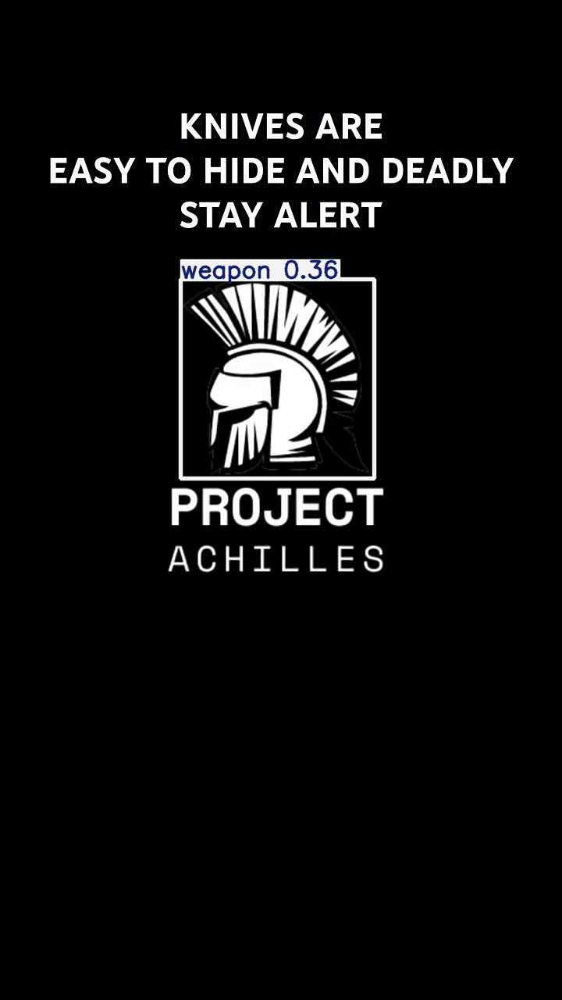

Frames processed: 350
Total frames: 354
Processing time: 15.79 seconds
Average processing FPS: 22.42


In [ ]:
import cv2
import time
from ultralytics import YOLO
from IPython.display import display, clear_output
from PIL import Image

VIDEO_PATH = "/content/test_video.mp4"
MODEL_PATH = "/content/runs/weapon/yolo11n_baseline/weights/best.pt"

model = YOLO(MODEL_PATH)
cap = cv2.VideoCapture(VIDEO_PATH)

if not cap.isOpened():
    raise RuntimeError("Could not open the test video.")

frame_count = 0
start = time.perf_counter()

while True:
    success, frame = cap.read()
    if not success:
        break

    result = model.predict(
        frame,
        imgsz=640,
        conf=0.25,
        device=0,
        verbose=False
    )[0]

    annotated = result.plot()
    frame_count += 1

    # Display every 10th frame to avoid excessive notebook output
    if frame_count % 10 == 0:
        clear_output(wait=True)
        display(Image.fromarray(cv2.cvtColor(
            annotated, cv2.COLOR_BGR2RGB
        )))
        print(f"Frames processed: {frame_count}")

elapsed = time.perf_counter() - start
cap.release()

print(f"Total frames: {frame_count}")
print(f"Processing time: {elapsed:.2f} seconds")
print(f"Average processing FPS: {frame_count / elapsed:.2f}")

Running YOLO + ByteTrack

It will process existing video, save an annotated output, and create a CSV containing tracked detections. Detects objects and tries to track the same objects across frames

In [ ]:
from ultralytics import YOLO
from pathlib import Path
import csv

VIDEO_PATH = "/content/test_video.mp4"
MODEL_PATH = "/content/runs/weapon/yolo11n_baseline/weights/best.pt"
OUTPUT_DIR = Path("/content/runs/weapon/tracking_demo")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

model = YOLO(MODEL_PATH)

results = model.track(
    source=VIDEO_PATH,
    tracker="bytetrack.yaml",
    imgsz=640,
    conf=0.25,
    device=0,
    save=True,
    project=str(OUTPUT_DIR),
    name="annotated",
    exist_ok=True,
    stream=True,
    verbose=False
)

csv_path = OUTPUT_DIR / "tracked_detections.csv"
frame_count = 0
record_count = 0

with csv_path.open("w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow([
        "frame", "timestamp_seconds", "track_id",
        "class_name", "confidence",
        "x1", "y1", "x2", "y2"
    ])

    for result in results:
        frame_count += 1
        fps = result.orig_shape  # Original frame dimensions
        video_fps = 30.0  # Replace with source FPS below if needed
        timestamp = (frame_count - 1) / video_fps

        if result.boxes is None:
            continue

        boxes = result.boxes
        ids = boxes.id

        for i, box in enumerate(boxes):
            # Skip detections without an assigned tracking ID
            if ids is None:
                continue

            track_id = int(ids[i].item())
            class_id = int(box.cls.item())
            class_name = model.names[class_id]
            confidence = float(box.conf.item())
            x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())

            writer.writerow([
                frame_count, round(timestamp, 3), track_id,
                class_name, round(confidence, 4),
                x1, y1, x2, y2
            ])
            record_count += 1

print(f"Frames processed: {frame_count}")
print(f"Tracked detection records: {record_count}")
print(f"CSV: {csv_path}")
print("Annotated video folder:", OUTPUT_DIR / "annotated")


requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
Using Python 3.13.15 environment at: /usr
Resolved 2 packages in 233ms
Prepared 1 package in 37ms
Installed 1 package in 2ms
 + lap==0.5.13

requirements: AutoUpdate success ✅ 0.6s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect

Results saved to /content/runs/weapon/tracking_demo/annotated
Frames processed: 354
Tracked detection records: 41
CSV: /content/runs/weapon/tracking_demo/tracked_detections.csv
Annotated video folder: /content/runs/weapon/tracking_demo/annotated


Generating weapon-event logs.

A separate CSV that logs only knife and weapon detections, grouped by track ID, to reduce repeated records.

In [ ]:
import pandas as pd
from pathlib import Path

input_csv = Path(
    "/content/runs/weapon/tracking_demo/tracked_detections.csv"
)
output_csv = Path(
    "/content/runs/weapon/tracking_demo/weapon_events.csv"
)

df = pd.read_csv(input_csv)

# Keep only weapon-related classes
weapons = df[df["class_name"].isin(["knife", "weapon"])].copy()

if weapons.empty:
    print("No tracked knife/weapon detections were recorded.")
else:
    # Group observations by track ID and class
    events = (
        weapons.groupby(["track_id", "class_name"], as_index=False)
        .agg(
            first_seen_seconds=("timestamp_seconds", "min"),
            last_seen_seconds=("timestamp_seconds", "max"),
            observations=("frame", "count"),
            max_confidence=("confidence", "max"),
        )
    )

    events.to_csv(output_csv, index=False)

    print("Weapon-related track groups:", len(events))
    print(events.to_string(index=False))
    print("Saved:", output_csv)

Weapon-related track groups: 3
 track_id class_name  first_seen_seconds  last_seen_seconds  observations  max_confidence
       13     weapon               8.400              8.400             1          0.3459
       17     weapon               9.700             10.000             8          0.5207
       31     weapon              11.133             11.767            20          0.3883
Saved: /content/runs/weapon/tracking_demo/weapon_events.csv


Adding a basic alert rule.

Flag a potential weapon event only when its maximum confidence is at least 0.45 and it appears in 3 or more tracked observations. These are provisional thresholds for testing, not validated security settings.

In [ ]:
import pandas as pd
from pathlib import Path

events_path = Path(
    "/content/runs/weapon/tracking_demo/weapon_events.csv"
)

df = pd.read_csv(events_path)

CONFIDENCE_THRESHOLD = 0.45
MIN_OBSERVATIONS = 3

df["potential_alert"] = (
    (df["max_confidence"] >= CONFIDENCE_THRESHOLD) &
    (df["observations"] >= MIN_OBSERVATIONS)
)

df["status"] = df["potential_alert"].map({
    True: "REVIEW_REQUIRED",
    False: "BELOW_DEMO_THRESHOLD"
})

output_path = events_path.parent / "alert_events.csv"
df.to_csv(output_path, index=False)

print(df[[
    "track_id", "class_name", "observations",
    "max_confidence", "status"
]].to_string(index=False))

print("\nSaved:", output_path)

 track_id class_name  observations  max_confidence               status
       13     weapon             1          0.3459 BELOW_DEMO_THRESHOLD
       17     weapon             8          0.5207      REVIEW_REQUIRED
       31     weapon            20          0.3883 BELOW_DEMO_THRESHOLD

Saved: /content/runs/weapon/tracking_demo/alert_events.csv


Visual weapon alert overlay

In [ ]:

from ultralytics import YOLO
from pathlib import Path
import cv2
import csv
import torch

# -----------------------------
# Paths
# -----------------------------
MODEL_PATH = "/content/runs/weapon/yolo11n_baseline/weights/best.pt"
VIDEO_PATH = "/content/test_video.mp4"

OUTPUT_DIR = Path("/content/runs/weapon/reliable_alert_demo")
EVIDENCE_DIR = OUTPUT_DIR / "evidence"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
EVIDENCE_DIR.mkdir(parents=True, exist_ok=True)

OUTPUT_VIDEO = str(OUTPUT_DIR / "weapon_alert_demo.mp4")
OUTPUT_CSV = OUTPUT_DIR / "incident_log.csv"

# -----------------------------
# Alert configuration
# -----------------------------
CONFIDENCE_THRESHOLD = 0.45
MIN_OBSERVATIONS = 3
MAX_GAP_FRAMES = 5
TARGET_CLASSES = {"weapon", "knife"}

DEVICE = 0 if torch.cuda.is_available() else "cpu"

model = YOLO(MODEL_PATH)

print("Device:", DEVICE)
print("Model classes:", model.names)

# -----------------------------
# Open input video
# -----------------------------
cap = cv2.VideoCapture(VIDEO_PATH)

if not cap.isOpened():
    raise RuntimeError(f"Could not open video: {VIDEO_PATH}")

fps = cap.get(cv2.CAP_PROP_FPS)
fps = fps if fps > 0 else 30.0

width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
cap.release()

writer = cv2.VideoWriter(
    OUTPUT_VIDEO,
    cv2.VideoWriter_fourcc(*"mp4v"),
    fps,
    (width, height)
)

if not writer.isOpened():
    raise RuntimeError("Could not create output video.")

# -----------------------------
# Tracking and incident state
# -----------------------------
track_state = {}
logged_incidents = set()

frame_count = 0
alert_frames = 0
incident_count = 0

with open(OUTPUT_CSV, "w", newline="") as csv_file:
    csv_writer = csv.DictWriter(
        csv_file,
        fieldnames=[
            "video_timestamp",
            "frame_number",
            "track_id",
            "class_name",
            "confidence",
            "evidence_path"
        ]
    )
    csv_writer.writeheader()

    results = model.track(
        source=VIDEO_PATH,
        tracker="bytetrack.yaml",
        imgsz=640,
        conf=0.25,
        device=DEVICE,
        stream=True,
        verbose=False
    )

    for result in results:
        frame = result.orig_img.copy()
        frame_count += 1
        active_alerts = []

        boxes = result.boxes

        if boxes is not None and boxes.id is not None:
            for i in range(len(boxes)):
                track_id = int(boxes.id[i].item())
                class_id = int(boxes.cls[i].item())
                class_name = str(
                    model.names[class_id]
                ).lower()
                confidence = float(boxes.conf[i].item())

                if class_name not in TARGET_CLASSES:
                    continue

                key = (track_id, class_name)

                state = track_state.get(key)

                # Start a fresh observation sequence after a long gap.
                if (
                    state is None
                    or frame_count - state["last_frame"]
                    > MAX_GAP_FRAMES
                ):
                    state = {
                        "count": 0,
                        "last_frame": frame_count,
                        "confirmed": False
                    }
                    track_state[key] = state

                # Count consecutive qualifying observations.
                if confidence >= CONFIDENCE_THRESHOLD:
                    state["count"] += 1
                else:
                    state["count"] = 0

                state["last_frame"] = frame_count

                if state["count"] >= MIN_OBSERVATIONS:
                    state["confirmed"] = True

                confirmed = state["confirmed"]

                x1, y1, x2, y2 = map(
                    int, boxes.xyxy[i].tolist()
                )

                if confirmed:
                    box_color = (0, 0, 255)
                    label = (
                        f"ALERT {class_name} "
                        f"ID:{track_id} {confidence:.2f}"
                    )
                    active_alerts.append(key)

                    # Log and save evidence only once per track/class.
                    if key not in logged_incidents:
                        timestamp = (frame_count - 1) / fps
                        minutes = int(timestamp // 60)
                        seconds = timestamp % 60
                        video_timestamp = (
                            f"{minutes:02d}:{seconds:06.3f}"
                        )

                        evidence_path = (
                            EVIDENCE_DIR
                            / f"incident_{incident_count + 1:04d}.jpg"
                        )

                        cv2.imwrite(
                            str(evidence_path), frame
                        )

                        csv_writer.writerow({
                            "video_timestamp": video_timestamp,
                            "frame_number": frame_count,
                            "track_id": track_id,
                            "class_name": class_name,
                            "confidence": round(confidence, 4),
                            "evidence_path": str(evidence_path)
                        })
                        csv_file.flush()

                        logged_incidents.add(key)
                        incident_count += 1

                        print(
                            f"ALERT: {class_name} | "
                            f"ID {track_id} | "
                            f"time {video_timestamp}"
                        )
                else:
                    box_color = (0, 200, 255)
                    label = (
                        f"{class_name} ID:{track_id} "
                        f"{confidence:.2f} "
                        f"obs:{state['count']}"
                    )

                cv2.rectangle(
                    frame,
                    (x1, y1),
                    (x2, y2),
                    box_color,
                    2
                )
                cv2.putText(
                    frame,
                    label,
                    (x1, max(25, y1 - 8)),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.55,
                    box_color,
                    2
                )

        if active_alerts:
            alert_frames += 1

            banner = "WEAPON ALERT - REVIEW REQUIRED"
            cv2.rectangle(
                frame, (0, 0), (width, 45), (0, 0, 180), -1
            )
            cv2.putText(
                frame,
                banner,
                (12, 30),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.8,
                (255, 255, 255),
                2
            )

        writer.write(frame)

writer.release()

print("\n--- DEMO SUMMARY ---")
print("Video saved:", OUTPUT_VIDEO)
print("Incident log:", OUTPUT_CSV)
print("Evidence folder:", EVIDENCE_DIR)
print("Frames processed:", frame_count)
print("Frames with alert banner:", alert_frames)
print("Logged track/class incidents:", incident_count)


Device: 0
Model classes: {0: 'knife', 1: 'person', 2: 'weapon'}

--- DEMO SUMMARY ---
Video saved: /content/runs/weapon/reliable_alert_demo/weapon_alert_demo.mp4
Incident log: /content/runs/weapon/reliable_alert_demo/incident_log.csv
Evidence folder: /content/runs/weapon/reliable_alert_demo/evidence
Frames processed: 354
Frames with alert banner: 0
Logged track/class incidents: 0


Previewing the output

In [ ]:

from IPython.display import Video, display

display(Video(
    "/content/runs/weapon/visual_alert_demo/weapon_alert_demo.mp4",
    embed=True,
    width=640
))


Downloading demo video

In [ ]:

from google.colab import files

files.download(
    "/content/runs/weapon/visual_alert_demo/weapon_alert_demo.mp4"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Test detection without tracking

In [ ]:

from ultralytics import YOLO
from collections import Counter
from pathlib import Path
import cv2

MODEL_PATH = "/content/runs/weapon/yolo11n_baseline/weights/best.pt"
VIDEO_PATH = "/content/test_video.mp4"
OUTPUT_PATH = "/content/runs/weapon/detection_diagnostic.mp4"

model = YOLO(MODEL_PATH)

cap = cv2.VideoCapture(VIDEO_PATH)
if not cap.isOpened():
    raise RuntimeError("Could not open the input video.")

fps = cap.get(cv2.CAP_PROP_FPS) or 30.0
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
cap.release()

Path(OUTPUT_PATH).parent.mkdir(parents=True, exist_ok=True)

writer = cv2.VideoWriter(
    OUTPUT_PATH,
    cv2.VideoWriter_fourcc(*"mp4v"),
    fps,
    (width, height)
)

class_counts = Counter()
class_max_conf = {}
frames_with_detections = Counter()
frame_count = 0

for result in model.predict(
    source=VIDEO_PATH,
    imgsz=640,
    conf=0.10,
    device=0,
    stream=True,
    verbose=False
):
    frame_count += 1
    annotated = result.plot()
    writer.write(annotated)

    if result.boxes is not None:
        for box in result.boxes:
            name = model.names[int(box.cls.item())]
            confidence = float(box.conf.item())

            class_counts[name] += 1
            class_max_conf[name] = max(
                class_max_conf.get(name, 0.0), confidence
            )
            frames_with_detections[name] += 1

writer.release()

print("Frames processed:", frame_count)
print("\nDetection counts at confidence 0.10:")
for name, count in class_counts.most_common():
    print(
        f"{name}: {count} detections, "
        f"max confidence={class_max_conf[name]:.3f}, "
        f"frames with detections={frames_with_detections[name]}"
    )

print("\nDiagnostic video:", OUTPUT_PATH)


Frames processed: 354

Detection counts at confidence 0.10:
weapon: 302 detections, max confidence=0.521, frames with detections=302
person: 166 detections, max confidence=0.430, frames with detections=166
knife: 1 detections, max confidence=0.265, frames with detections=1

Diagnostic video: /content/runs/weapon/detection_diagnostic.mp4


Verifying the alert visually

In [ ]:

from IPython.display import Video, display

display(Video(
    "/content/runs/weapon/detection_diagnostic.mp4",
    embed=True,
    width=640
))

Downloading the diagnostic video

In [ ]:
from google.colab import files

files.download(
    "/content/runs/weapon/detection_diagnostic.mp4"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Inspecting few frames directly inside here

Video duration: 11.9 seconds
Frame at 5 seconds


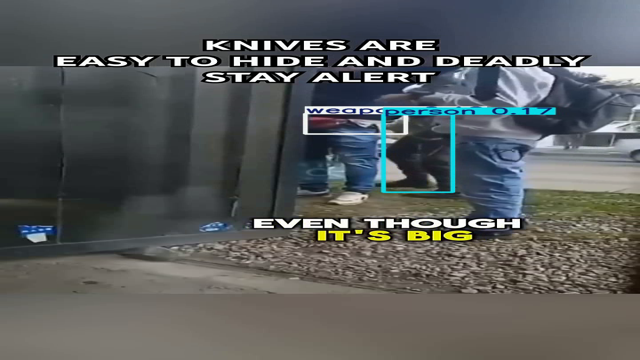

Frame at 8 seconds


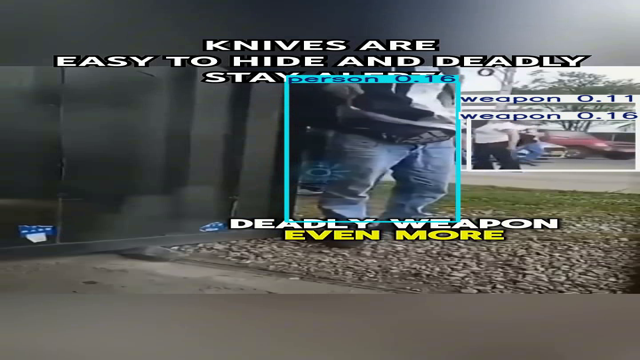

Frame at 10 seconds


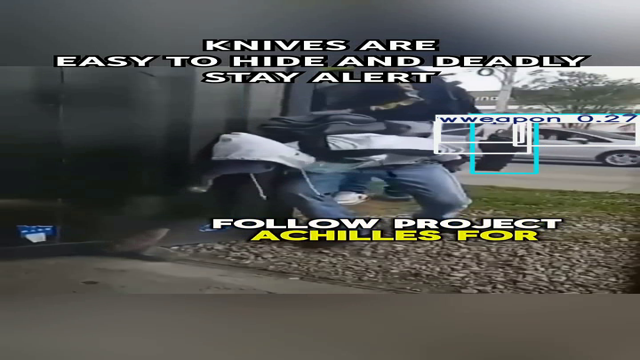

In [ ]:
from IPython.display import display
from PIL import Image
import cv2

video_path = "/content/runs/weapon/detection_diagnostic.mp4"
cap = cv2.VideoCapture(video_path)

fps = cap.get(cv2.CAP_PROP_FPS) or 30
duration = cap.get(cv2.CAP_PROP_FRAME_COUNT) / fps

print(f"Video duration: {duration:.1f} seconds")

for seconds in [5, 8, 10, 12]:
    cap.set(cv2.CAP_PROP_POS_MSEC, seconds * 1000)
    ok, frame = cap.read()

    if ok:
        frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        print(f"Frame at {seconds} seconds")
        display(Image.fromarray(frame).resize((640, 360)))

cap.release()

Running the diagnostic cell.

Testing the original video at three confidence thresholds and counts detections for each class.

In [ ]:

from ultralytics import YOLO
from collections import Counter

model = YOLO(
    "/content/runs/weapon/yolo11n_baseline/weights/best.pt"
)

video_path = "/content/test_video.mp4"

for threshold in [0.10, 0.25, 0.40]:
    counts = Counter()
    max_conf = {}

    for result in model.predict(
        source=video_path,
        conf=threshold,
        imgsz=640,
        device=0,
        stream=True,
        verbose=False
    ):
        if result.boxes is None:
            continue

        for box in result.boxes:
            name = model.names[int(box.cls.item())]
            score = float(box.conf.item())
            counts[name] += 1
            max_conf[name] = max(max_conf.get(name, 0), score)

    print(f"\nConfidence threshold: {threshold}")
    print("Detection counts:", dict(counts))
    print("Maximum confidence:", {
        k: round(v, 3) for k, v in max_conf.items()
    })



Confidence threshold: 0.1
Detection counts: {'weapon': 302, 'person': 166, 'knife': 1}
Maximum confidence: {'weapon': 0.521, 'person': 0.43, 'knife': 0.265}

Confidence threshold: 0.25
Detection counts: {'person': 20, 'weapon': 51, 'knife': 1}
Maximum confidence: {'person': 0.43, 'weapon': 0.521, 'knife': 0.265}

Confidence threshold: 0.4
Detection counts: {'person': 2, 'weapon': 7}
Maximum confidence: {'person': 0.43, 'weapon': 0.521}


Running the diagnostic cell to check whether the issue is confidence, tracking or three-observation rule.

In [ ]:
from ultralytics import YOLO
from collections import defaultdict

MODEL_PATH = "/content/runs/weapon/yolo11n_baseline/weights/best.pt"
VIDEO_PATH = "/content/test_video.mp4"

model = YOLO(MODEL_PATH)

# Track low-confidence detections too, for diagnosis.
results = model.track(
    source=VIDEO_PATH,
    tracker="bytetrack.yaml",
    imgsz=640,
    conf=0.10,
    device=0,
    stream=True,
    persist=False,
    verbose=False
)

thresholds = [0.10, 0.25, 0.35, 0.45]
target_classes = {"weapon", "knife"}

total_frames = 0
target_detections = 0
frames_with_targets = 0
tracked_target_detections = 0

max_conf = defaultdict(float)
detections_above = defaultdict(int)
track_sequences = defaultdict(list)
tracked_frames = defaultdict(list)

for frame_idx, result in enumerate(results, start=1):
    total_frames += 1
    found_target_this_frame = False

    boxes = result.boxes
    if boxes is None:
        continue

    for i in range(len(boxes)):
        class_id = int(boxes.cls[i].item())
        class_name = str(model.names[class_id]).lower()
        confidence = float(boxes.conf[i].item())

        if class_name not in target_classes:
            continue

        target_detections += 1
        found_target_this_frame = True
        max_conf[class_name] = max(
            max_conf[class_name], confidence
        )

        for threshold in thresholds:
            if confidence >= threshold:
                detections_above[(class_name, threshold)] += 1

        if boxes.id is not None:
            track_id = int(boxes.id[i].item())
            tracked_target_detections += 1
            key = (track_id, class_name)

            track_sequences[key].append(
                (frame_idx, confidence)
            )
            tracked_frames[key].append(frame_idx)

    if found_target_this_frame:
        frames_with_targets += 1

print("Total frames:", total_frames)
print("Frames with target detections:", frames_with_targets)
print("Total target detections:", target_detections)
print("Target detections with track IDs:", tracked_target_detections)

print("\nMaximum confidence by class:")
for name in sorted(target_classes):
    print(name, round(max_conf[name], 3))

print("\nDetections above each confidence threshold:")
for name in sorted(target_classes):
    for threshold in thresholds:
        print(
            f"{name}, threshold={threshold}:",
            detections_above[(name, threshold)]
        )

print("\nTrack summary:")
if not track_sequences:
    print("No weapon/knife tracks received IDs.")
else:
    for key, observations in sorted(track_sequences.items()):
        track_id, class_name = key
        frames = [f for f, _ in observations]
        confidences = [c for _, c in observations]

        # Longest run of consecutive qualifying frames.
        longest_run = 0
        current_run = 0
        previous_frame = None

        for frame, conf in observations:
            if (
                conf >= 0.45
                and (
                    previous_frame is None
                    or frame == previous_frame + 1
                )
            ):
                current_run += 1
            elif conf >= 0.45:
                current_run = 1
            else:
                current_run = 0

            longest_run = max(longest_run, current_run)
            previous_frame = frame

        print(
            f"ID={track_id}, class={class_name}, "
            f"detections={len(observations)}, "
            f"max_conf={max(confidences):.3f}, "
            f"longest_consecutive_run_at_0.45={longest_run}"
        )

In [ ]:

for (track_id, class_name), observations in sorted(track_sequences.items()):
    if track_id in (17, 32):
        print(f"\nTrack ID: {track_id} | Class: {class_name}")
        for frame_number, confidence in observations:
            print(
                f"Frame {frame_number:3d} | "
                f"Confidence: {confidence:.3f}"
            )



Track ID: 17 | Class: weapon
Frame 292 | Confidence: 0.416
Frame 293 | Confidence: 0.439
Frame 294 | Confidence: 0.440
Frame 295 | Confidence: 0.521
Frame 296 | Confidence: 0.418
Frame 297 | Confidence: 0.410
Frame 298 | Confidence: 0.268
Frame 299 | Confidence: 0.194
Frame 300 | Confidence: 0.203

Track ID: 32 | Class: weapon
Frame 335 | Confidence: 0.388
Frame 336 | Confidence: 0.360
Frame 337 | Confidence: 0.328
Frame 338 | Confidence: 0.327
Frame 339 | Confidence: 0.324
Frame 340 | Confidence: 0.328
Frame 341 | Confidence: 0.330
Frame 342 | Confidence: 0.330
Frame 343 | Confidence: 0.330
Frame 344 | Confidence: 0.330
Frame 345 | Confidence: 0.330
Frame 346 | Confidence: 0.330
Frame 347 | Confidence: 0.330
Frame 348 | Confidence: 0.330
Frame 349 | Confidence: 0.331
Frame 350 | Confidence: 0.364
Frame 351 | Confidence: 0.364
Frame 352 | Confidence: 0.364
Frame 353 | Confidence: 0.364
Frame 354 | Confidence: 0.364


In [ ]:

from ultralytics import YOLO
from pathlib import Path

model_path = Path("/content/drive/MyDrive/WeaponDetection/best.pt")

if model_path.exists():
    model = YOLO(str(model_path))
    print("Model loaded successfully")
    print("Classes:", model.names)
    print("Task:", model.task)
else:
    print("Model not found. Check the path:", model_path)


Model loaded successfully
Classes: {0: 'knife', 1: 'person', 2: 'weapon'}
Task: detect


In [ ]:

from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


Exporting model to ONNX from CPU

ONNX is a portable model format that we can prepare for later NVIDIA DeepStream integration.

In [ ]:

from ultralytics import YOLO
from pathlib import Path

MODEL_PATH = "/content/drive/MyDrive/WeaponDetection/best.pt"

model = YOLO(MODEL_PATH)

onnx_path = model.export(
    format="onnx",
    imgsz=640,
    device="cpu",
    simplify=False
)

print("Export result:", onnx_path)
print("File exists:", Path(onnx_path).exists())


Ultralytics 8.4.175 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO11n summary (fused): 101 layers, 2,597,537 parameters, 0 gradients, 6.4 GFLOPs

PyTorch: starting from '/content/drive/MyDrive/WeaponDetection/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 7, 8400) (5.2 MB)
requirements: Ultralytics requirement ['onnx>=1.12.0,<2.0.0'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 5 packages in 606ms
Prepared 1 package in 428ms
Installed 1 package in 57ms
 + onnx==1.23.2

requirements: AutoUpdate success ✅ 1.6s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.23.2 opset 18...
ONNX: export success ✅ 3.1s, saved as '/content/drive/MyDrive/WeaponDetection/best.onnx' (10.1 MB)

Export complete (

In [ ]:

!pip install -q onnxruntime


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 44.8 MB/s eta 0:00:00


Searching project folder for few imaages


In [ ]:

from pathlib import Path

root = Path("/content/drive/MyDrive/WeaponDetection")
extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

images = [
    p for p in root.rglob("*")
    if p.is_file() and p.suffix.lower() in extensions
][:10]

print("Images found:", len(images))
for image in images:
    print(image)


Images found: 0


Locating the dataset

In [ ]:

from pathlib import Path

drive = Path("/content/drive/MyDrive")

for path in drive.rglob("data.yaml"):
    print(path)


Locating dataset configuration

In [ ]:

from pathlib import Path

drive = Path("/content/drive/MyDrive")
targets = {"data.yaml", "best.pt", "last.pt", "best.onnx"}

for path in drive.rglob("*"):
    if path.is_file() and path.name in targets:
        print(path)


/content/drive/MyDrive/WeaponDetection/best.pt
/content/drive/MyDrive/WeaponDetection/best.onnx


Verifying onnx interference

In [ ]:

import onnxruntime as ort

onnx_path = "/content/drive/MyDrive/WeaponDetection/best.onnx"

session = ort.InferenceSession(
    onnx_path,
    providers=["CPUExecutionProvider"]
)

print("ONNX model loaded successfully!")

print("\nInputs:")
for item in session.get_inputs():
    print(item.name, item.shape, item.type)

print("\nOutputs:")
for item in session.get_outputs():
    print(item.name, item.shape, item.type)


ONNX model loaded successfully!

Inputs:
images [1, 3, 640, 640] tensor(float)

Outputs:
output0 [1, 7, 8400] tensor(float)


In [ ]:

from google.colab import files

uploaded = files.upload()


Saving 11.jpg to 11.jpg


Running detection on a selected image

Loading /content/drive/MyDrive/WeaponDetection/best.onnx for ONNX Runtime inference...
Using ONNX Runtime 1.31.0 with CPUExecutionProvider

image 1/1 /content/11.jpg: 640x640 1 weapon, 230.4ms
Speed: 56.0ms preprocess, 230.4ms inference, 48.9ms postprocess per image at shape (1, 3, 640, 640)

Detected objects: 1
Class: weapon | Confidence: 0.862 | Box: [23.091062545776367, 16.13156509399414, 212.3566131591797, 121.3919448852539]


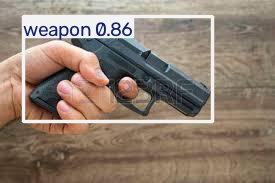

In [ ]:

from ultralytics import YOLO
from IPython.display import display
from PIL import Image
from pathlib import Path

model_path = "/content/drive/MyDrive/WeaponDetection/best.onnx"
image_path = "/content/drive/MyDrive/11.jpg"

# Colab uploaded 11.jpg to /content, not your Google Drive
if not Path(image_path).exists():
    image_path = "/content/11.jpg"

model = YOLO(model_path, task="detect")

results = model.predict(
    source=image_path,
    imgsz=640,
    conf=0.25,
    device="cpu",
    verbose=True
)

result = results[0]

print("\nDetected objects:", len(result.boxes))

for box in result.boxes:
    class_id = int(box.cls[0])
    confidence = float(box.conf[0])
    print(
        f"Class: {model.names[class_id]} | "
        f"Confidence: {confidence:.3f} | "
        f"Box: {box.xyxy[0].tolist()}"
    )

# Display annotated image
annotated = result.plot()
display(Image.fromarray(annotated[:, :, ::-1]))


Inspecting onnx metadata

In [ ]:

!pip install -q onnx

import onnx

model_path = "/content/drive/MyDrive/WeaponDetection/best.onnx"
model = onnx.load(model_path)

onnx.checker.check_model(model)

print("ONNX validation: PASS")
print("IR version:", model.ir_version)

for opset in model.opset_import:
    print("Opset:", opset.domain or "ai.onnx", opset.version)

print("\nInputs:")
for item in model.graph.input:
    print(item.name, [
        d.dim_value if d.dim_value else d.dim_param
        for d in item.type.tensor_type.shape.dim
    ])

print("\nOutputs:")
for item in model.graph.output:
    print(item.name, [
        d.dim_value if d.dim_value else d.dim_param
        for d in item.type.tensor_type.shape.dim
    ])


ONNX validation: PASS
IR version: 8
Opset: ai.onnx 18

Inputs:
images [1, 3, 640, 640]

Outputs:
output0 [1, 7, 8400]


Checking model's export setting

In [ ]:

import onnx

model_path = "/content/drive/MyDrive/WeaponDetection/best.onnx"
model = onnx.load(model_path)

print("Model metadata:")
for item in model.metadata_props:
    print(f"{item.key}: {item.value}")

print("\nFirst 25 graph operations:")
for node in model.graph.node[:25]:
    print(node.op_type, "->", list(node.output))

print("\nLast 20 graph operations:")
for node in model.graph.node[-20:]:
    print(node.op_type, "->", list(node.output))


Model metadata:
description: Ultralytics YOLO11n model trained on /content/weapon-detection-yolo/data.yaml
author: Ultralytics
date: 2026-10-10T17:13:37.376971+00:00
version: 8.4.175
license: AGPL-3.0 License (https://ultralytics.com/license)
docs: https://docs.ultralytics.com
stride: 32
task: detect
head: Detect
batch: 1
imgsz: [640, 640]
names: {0: 'knife', 1: 'person', 2: 'weapon'}
args: {'data': None, 'batch': 1, 'fraction': 1.0, 'quantize': None, 'nms': None, 'dynamic': False, 'simplify': False, 'opset': None}
channels: 3
end2end: False

First 25 graph operations:
Conv -> ['/model.0/conv/Conv_output_0']
Sigmoid -> ['/model.0/act/Sigmoid_output_0']
Mul -> ['/model.0/act/Mul_output_0']
Conv -> ['/model.1/conv/Conv_output_0']
Sigmoid -> ['/model.1/act/Sigmoid_output_0']
Mul -> ['/model.1/act/Mul_output_0']
Conv -> ['/model.2/cv1/conv/Conv_output_0']
Sigmoid -> ['/model.2/cv1/act/Sigmoid_output_0']
Mul -> ['/model.2/cv1/act/Mul_output_0']
Constant -> ['onnx::Split_185']
Split -> ['/mo

Verifying the output format to inspect the raw ONNX output and compare it with the detections returned by Ultralytics.

In [ ]:

import onnxruntime as ort
import numpy as np

model_path = "/content/drive/MyDrive/WeaponDetection/best.onnx"
image_path = "/content/11.jpg"

session = ort.InferenceSession(
    model_path,
    providers=["CPUExecutionProvider"]
)

print("Input:", session.get_inputs()[0].shape)
print("Output:", session.get_outputs()[0].shape)

# Use Ultralytics to prepare the image exactly as it normally does.
from ultralytics import YOLO

model = YOLO(model_path)
result = model.predict(
    source=image_path,
    imgsz=640,
    conf=0.25,
    verbose=False
)[0]

# Get the raw ONNX output using the same preprocessing as Ultralytics.
from ultralytics.data.augment import LetterBox
from ultralytics.utils import ops
import cv2

img = cv2.imread(image_path)
img = LetterBox(new_shape=(640, 640))(image=img)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
img = img.transpose(2, 0, 1)
img = np.ascontiguousarray(img, dtype=np.float32) / 255.0
img = img[None]

raw = session.run(None, {"images": img})[0]

print("\nRaw output shape:", raw.shape)
print("Raw output sample:", raw[0, :, :5])

print("\nUltralytics postprocessed detections:")
if result.boxes is not None and len(result.boxes) > 0:
    for box in result.boxes:
        class_id = int(box.cls[0])
        print(
            model.names[class_id],
            "confidence =", round(float(box.conf[0]), 3),
            "box =", box.xyxy[0].tolist()
        )
else:
    print("No detections")


Input: [1, 3, 640, 640]
Output: [1, 7, 8400]
Loading /content/drive/MyDrive/WeaponDetection/best.onnx for ONNX Runtime inference...
Using ONNX Runtime 1.31.0 with CPUExecutionProvider

Raw output shape: (1, 7, 8400)
Raw output sample: [[     4.6454      10.709      22.278      36.875      46.144]
 [     15.564      6.6793      5.9264      8.1145      10.244]
 [     12.534      21.121      50.241      82.651       98.71]
 [     38.375       12.61      11.034      15.798      20.491]
 [ 4.7684e-07  5.9605e-08           0  5.9605e-08  1.1921e-07]
 [ 5.7518e-06  1.4603e-06  3.5763e-07  2.0862e-07  3.5763e-07]
 [ 1.3709e-06  6.2585e-07  2.9802e-07  1.7881e-07  1.7881e-07]]

Ultralytics postprocessed detections:
weapon confidence = 0.862 box = [23.091062545776367, 16.13156509399414, 212.3566131591797, 121.3919448852539]


Exporting an ONNX model with NMS included

In [ ]:

from ultralytics import YOLO
from pathlib import Path

model = YOLO("/content/drive/MyDrive/WeaponDetection/best.pt")

exported_path = model.export(
    format="onnx",
    imgsz=640,
    batch=1,
    nms=True,
    dynamic=False
)

print("Exported model:", exported_path)
print("File exists:", Path(str(exported_path)).exists())


Ultralytics 8.4.175 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLO11n summary (fused): 101 layers, 2,597,537 parameters, 0 gradients, 6.4 GFLOPs

PyTorch: starting from '/content/drive/MyDrive/WeaponDetection/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 300, 6) (5.2 MB)
requirements: Ultralytics requirement ['onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 10 packages in 787ms
Prepared 2 packages in 73ms
Installed 2 packages in 22ms
 + colorama==0.4.6
 + onnxslim==0.1.98

requirements: AutoUpdate success ✅ 1.2s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.23.2 opset 18...
ONNX: slimming with onnxslim 0.1.98...
ONNX: export success ✅ 9.5s, saved as '/content/drive/MyDrive/WeaponDetection/best.onnx' (10.2 MB)

Export complete (10.0s)
Results saved to /content/drive/MyDrive/WeaponDetection/best.onnx
Predict:

Checking onnx overwritten file

In [ ]:

import onnx
import onnxruntime as ort

path = "/content/drive/MyDrive/WeaponDetection/best.onnx"

model = onnx.load(path)
onnx.checker.check_model(model)

print("ONNX validation: PASS")
print("\nMetadata:")
for item in model.metadata_props:
    print(f"{item.key}: {item.value}")

session = ort.InferenceSession(
    path,
    providers=["CPUExecutionProvider"]
)

print("\nInputs:")
for item in session.get_inputs():
    print(item.name, item.shape, item.type)

print("\nOutputs:")
for item in session.get_outputs():
    print(item.name, item.shape, item.type)


ONNX validation: PASS

Metadata:
description: Ultralytics YOLO11n model trained on /content/weapon-detection-yolo/data.yaml
author: Ultralytics
date: 2026-10-10T17:43:03.704899+00:00
version: 8.4.175
license: AGPL-3.0 License (https://ultralytics.com/license)
docs: https://docs.ultralytics.com
stride: 32
task: detect
head: Detect
batch: 1
imgsz: [640, 640]
names: {0: 'knife', 1: 'person', 2: 'weapon'}
args: {'data': None, 'batch': 1, 'fraction': 1.0, 'quantize': None, 'nms': True, 'dynamic': False, 'simplify': True, 'opset': None}
channels: 3
end2end: False

Inputs:
images [1, 3, 640, 640] tensor(float)

Outputs:
output0 [1, 300, 6] tensor(float)


Verifying the new output on test image


In [ ]:

import onnxruntime as ort
import numpy as np
import cv2

model_path = "/content/drive/MyDrive/WeaponDetection/best.onnx"
image_path = "/content/11.jpg"

session = ort.InferenceSession(
    model_path,
    providers=["CPUExecutionProvider"]
)

image = cv2.imread(image_path)
assert image is not None, f"Could not read {image_path}"

# Ultralytics-style letterbox preprocessing
from ultralytics.data.augment import LetterBox

processed = LetterBox(new_shape=(640, 640))(image=image)
processed = cv2.cvtColor(processed, cv2.COLOR_BGR2RGB)
processed = processed.transpose(2, 0, 1)
processed = np.ascontiguousarray(processed, dtype=np.float32) / 255.0
processed = processed[None]

output = session.run(None, {"images": processed})[0]

print("Output shape:", output.shape)
print("First 5 output rows:")
print(output[0, :5])

print("\nNon-zero rows:", np.count_nonzero(np.any(output[0] != 0, axis=1)))


Output shape: (1, 300, 6)
First 5 output rows:
[[     53.739      144.55      494.21      389.58     0.86229           2]
 [          0           0           0           0           0           0]
 [          0           0           0           0           0           0]
 [          0           0           0           0           0           0]
 [          0           0           0           0           0           0]]

Non-zero rows: 1


Saving a verified model for having copies of original and NMS-enabled version

In [ ]:

from pathlib import Path
import shutil
import onnx
import onnxruntime as ort

source = Path("/content/drive/MyDrive/WeaponDetection/best.onnx")
destination = Path(
    "/content/drive/MyDrive/WeaponDetection/best_nms.onnx"
)

shutil.copy2(source, destination)

# Validate the saved copy
onnx.checker.check_model(onnx.load(str(destination)))

session = ort.InferenceSession(
    str(destination),
    providers=["CPUExecutionProvider"]
)

print("Saved:", destination)
print("File size (MB):", round(destination.stat().st_size / (1024 * 1024), 2))
print("Input:", session.get_inputs()[0].shape)
print("Output:", session.get_outputs()[0].shape)
print("Providers:", session.get_providers())


Saved: /content/drive/MyDrive/WeaponDetection/best_nms.onnx
File size (MB): 10.2
Input: [1, 3, 640, 640]
Output: [1, 300, 6]
Providers: ['CPUExecutionProvider']


Running RTSP prototype using trained model

In [ ]:
import cv2
import time
from ultralytics import YOLO

# Use the actual RTSP URL from your authorized camera.
RTSP_URL = "rtsp://CAMERA_IP:554/stream_path"

MODEL_PATH = "best.pt"
model = YOLO(MODEL_PATH)

cap = cv2.VideoCapture(RTSP_URL, cv2.CAP_FFMPEG)

if not cap.isOpened():
    raise RuntimeError("Could not connect to the CCTV stream.")

frame_count = 0
start_time = time.perf_counter()

try:
    while True:
        success, frame = cap.read()

        if not success:
            print("Frame unavailable; stream may have disconnected.")
            break

        result = model.predict(
            frame,
            imgsz=640,
            conf=0.25,
            verbose=False
        )[0]

        annotated_frame = result.plot()

        cv2.imshow("CCTV Weapon Detection", annotated_frame)
        frame_count += 1

        if cv2.waitKey(1) & 0xFF == ord("q"):
            break

finally:
    cap.release()
    cv2.destroyAllWindows()

elapsed = time.perf_counter() - start_time

if elapsed > 0:
    print(f"Processed frames: {frame_count}")
    print(f"Average processing FPS: {frame_count / elapsed:.2f}")

Setting up a deepstraam pipeline


In [1]:

import os
import platform
import subprocess

print("OS:", platform.platform())
print("Python:", platform.python_version())

def check(command):
    result = subprocess.run(
        command,
        shell=True,
        capture_output=True,
        text=True
    )
    print(f"\n$ {command}")
    print(result.stdout or result.stderr or "(no output)")
    print("Exit code:", result.returncode)

check("nvidia-smi")
check("nvcc --version")
check("which deepstream-app")
check("docker --version")
check("lsb_release -a")


OS: Linux-6.6.122+-x86_64-with-glibc2.39
Python: 3.13.15

$ nvidia-smi
Sun Oct 11 07:30:51 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   44C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        | 

Checking whether the deepstream can be installed or not

In [7]:
import os
import torch

print("PyTorch:", torch.__version__)
print("CUDA available in PyTorch:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("\nModel files:")
folder = "/content/drive/MyDrive/WeaponDetection"

if os.path.exists(folder):
    for f in os.listdir(folder):
        if f.endswith((".onnx", ".pt", ".engine")):
            print(f)
else:
    print("WeaponDetection folder not found")


PyTorch: 2.11.0+cu130
CUDA available in PyTorch: True
GPU: Tesla T4

Model files:
best.pt
best_nms.onnx
best.onnx


Mounting google drive

In [4]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [6]:
import os

folder = "/content/drive/MyDrive/WeaponDetection"

print("Folder exists:", os.path.exists(folder))

if os.path.exists(folder):
    for root, dirs, files in os.walk(folder):
        for file in files:
            if file.endswith((".pt", ".onnx", ".engine", ".mp4", ".avi")):
                print(os.path.join(root, file))

Folder exists: True
/content/drive/MyDrive/WeaponDetection/best.pt
/content/drive/MyDrive/WeaponDetection/best_nms.onnx
/content/drive/MyDrive/WeaponDetection/best.onnx


Testing best_nms.onnx on the Tesla T4 GPU

In [9]:
!pip -q install onnxruntime-gpu opencv-python-headless


Checking the GPU accelerated onnx inference

In [10]:

import onnxruntime as ort

print("ONNX Runtime:", ort.__version__)
print("Available providers:", ort.get_available_providers())

model_path = "/content/drive/MyDrive/WeaponDetection/best_nms.onnx"

session = ort.InferenceSession(
    model_path,
    providers=["CUDAExecutionProvider", "CPUExecutionProvider"]
)

print("Session providers:", session.get_providers())
print("Input:", session.get_inputs()[0].shape)
print("Output:", session.get_outputs()[0].shape)


ONNX Runtime: 1.31.0
Available providers: ['TensorrtExecutionProvider', 'CUDAExecutionProvider', 'CPUExecutionProvider']
Session providers: ['CUDAExecutionProvider', 'CPUExecutionProvider']
Input: [1, 3, 640, 640]
Output: [1, 300, 6]


In [12]:

import os

for path in [
    "/opt/nvidia/deepstream",
    "/usr/local/deepstream",
    "/opt/nvidia/deepstream/deepstream"
]:
    print(path, "->", os.path.exists(path))


/opt/nvidia/deepstream -> False
/usr/local/deepstream -> False
/opt/nvidia/deepstream/deepstream -> False


Exporting a batch size 2 onnx model

In [15]:

%pip install -q ultralytics onnx

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 32.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 105.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 9.7 MB/s eta 0:00:00


In [16]:

from ultralytics import YOLO
from pathlib import Path
import shutil

drive_folder = Path("/content/drive/MyDrive/WeaponDetection")
model_path = drive_folder / "best.pt"

assert model_path.exists(), f"Model not found: {model_path}"

model = YOLO(str(model_path))

exported_path = model.export(
    format="onnx",
    imgsz=640,
    batch=2,
    nms=True,
    dynamic=False
)

destination = drive_folder / "best_nms_b2.onnx"
shutil.copy2(exported_path, destination)

print("Exported model:", destination)
print("Model exists:", destination.exists())
print("Model size (MB):", round(destination.stat().st_size / (1024 * 1024), 2))


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO11n summary (fused): 101 layers, 2,597,537 parameters, 0 gradients, 6.4 GFLOPs

PyTorch: starting from '/content/drive/MyDrive/WeaponDetection/best.pt' with input shape (2, 3, 640, 640) BCHW and output shape(s) (2, 300, 6) (5.2 MB)
requirements: Ultralytics requirement ['onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.13.15 environment at: /usr
Resolved 10 packages in 257ms
Prepared 2 packages in 29ms
Installed 2 packages in 6ms
 + colorama==0.4.6
 

Verifying the exported model

In [17]:

import onnxruntime as ort

path = "/content/drive/MyDrive/WeaponDetection/best_nms_b2.onnx"

session = ort.InferenceSession(
    path,
    providers=["CUDAExecutionProvider", "CPUExecutionProvider"]
)

print("Input shape:", session.get_inputs()[0].shape)
print("Output shape:", session.get_outputs()[0].shape)
print("Providers:", session.get_providers())


Input shape: [2, 3, 640, 640]
Output shape: [2, 300, 6]
Providers: ['CUDAExecutionProvider', 'CPUExecutionProvider']
